# Homework 7 — Logistic Regression, Decision Trees & Random Forests

## Due: 10/22


## Part 1 — Conceptual Understanding


**Q1** What are the differences among a root node, an internal (decision) node, and a leaf node in a Decision Tree?

**Q2** How does a leaf node make predictions in a Decision Tree for both classification and regression problem?

**Q3** Why can a deep Decision Tree overfit the training data? Describe methods to control the complexity of a Decision Tree.

**Q4** What are the two sources of randomness in a Random Forest? Explain how they help improve the performance of a Random Forest compared with a single Decision Tree.



## Answers

### Q1

Root nodes are the top nodes that receive all the training data and for the first split. Internal nodes are non-leaf
nodes that test a feature in the dataset and route examples to child nodes based on the result. The root node is
actually also a decision node when the tree has splits. A leaf node is a node with no children and that makes a
prediction.

### Q2

For classification, a leaf typically predicts the most common class among the training examples that reached it.
Class probabilities can be estimated using the proportion of examples belonging to each class. For regression,
a leaf typically predicts the mean value of the training examples that reached it when the tree uses squared error loss.
If using absolute error loss, it's the median.

### Q3

A deep tree can create a lot of small regions that capture noise and unusual examples in the training data.
This can produce very low training error but poor predictions on unseen data.

To control the complexity, we can limit the maximum depth, we can increase the minimum number of samples required to split a node or remain in a leaf, we can limit the maximum number of leaf nodes, or prune branches after training.

### Q4

One is Bootstrap Sampling, each tree trains on a random sample of the training data drawn with replacement. The other is random feature selection, at each split, the tree considers a random subset of features when choosing the best split.

These choices make diverse trees with less correlated errors. And so combining their predictions with majority voting for classification or averaging for regression reduces the variance and usually improves generalization compared with a single decision tree.

## Part 2 — Logistic Regression
A trained model uses two standardized sensor features:

$$
z=-2+0.8x_1+1.2x_2,\qquad 
$$
$$
P(\mathrm{Faulty}\mid\mathbf{x})=\sigma(z)=\frac{1}{1+e^{-z}}.
$$

For one machine, $x_1=1$ (temperature) and $x_2=2$ (vibration).

**Q5** Calculate $z$ and $P(\mathrm{Faulty}\mid\mathbf{x})$.

**Q6** Predict the class with a threshold of 0.5. What happens if the threshold changes to 0.8? 

**Q7** The true label is $y=1$. Compute the binary cross-entropy loss
$
L=-[y\ln(p)+(1-y)\ln(1-p)].
$

**Q8** Explain why lowering the decision threshold can increase recall for Faulty machines, but may also increase false alarms.




## Answers

### Q5

$$
z = -2 + 0.8 * 1 + 1.2 * 2 = 1.2
$$

$$
P(Faulty | X) = \frac{1}{1 + e^{-1.2}} = 0.769
$$

### Q6

With 0.5 threshold, the classification yields Faulty. With threshold 0.8, the classification yields Not Faulty

### Q7

$$
L = -[1 \times ln(0.769) + (1 - 1) \times ln(1 - 0.769)] = 0.263
$$

### Q8

Lowering the decision threshold means a machine needs a lower predicted probability of being Faulty to be
classified as faulty. This catches more actual faulty machines, reducing false negatives and increasing recall.

However, more healthy machines can also exceed the lower threshold and be incorrectly flagged as faulty, increasing
false positives.

## Part 3 — Decision Tree
Use the eight observations below. The positive class is **Faulty**.

| Sample | Temperature (°C) | Vibration (mm/s) | Condition |
|---:|---:|---:|---|
| 1 | 60 | 0.4 | Healthy |
| 2 | 78 | 0.7 | Healthy |
| 3 | 58 | 1.9 | Healthy |
| 4 | 66 | 1.1 | Healthy |
| 5 | 82 | 1.3 | Faulty |
| 6 | 70 | 1.6 | Healthy |
| 7 | 74 | 1.9 | Faulty |
| 8 | 68 | 2.1 | Faulty |

For a node with class proportions $p_H,p_F$, $G=1-p_H^2-p_F^2$. For a candidate split,
$
G_{\mathrm{weighted}}=\frac{n_L}{n}G_L+\frac{n_R}{n}G_R.
$

**Q9** Calculate the Gini impurity of the root node.

**Q10** Evaluate these candidate splits **by hand**. For each, report left/right class counts, child Gini values, and weighted Gini:
- Temperature ≤ 72°C
- Temperature ≤ 80°C
- Vibration ≤ 1.2 mm/s

Then fill out the following table


| Split | Left H/F | Right H/F | Left Gini | Right Gini | Weighted Gini |
|---|---:|---:|---:|---:|---:|
| Temperature ≤ 72 | 4 / 1 | 1 / 2 | 0.32 | 0.444 | 0.367 |
| Temperature ≤ 80 | 5 / 2 | 0 / 1 | 0.408 | 0 | 0.357 |
| Vibration ≤ 1.2 | 3 / 0 | 2 / 3 | 0 | 0.48 | 0.300 |



**Q11** Which of these splits is best? Explain why.






**Q12** Finish the following code

## Answers

### Q9

$$
G = 1 - (\frac{5}{8})^2 - (\frac{3}{8})^2 = 0.47
$$

### Q10

Temperature <= 72C:

$$
G_L = 1 - (\frac{4}{5})^2 - (\frac{1}{5})^2 = 0.32
$$

$$
G_R = 1 - (\frac{1}{3})^2 - (\frac{2}{3})^2 = 0.44
$$

$$
G_{weighted} = \frac{5}{8} * 0.32 + \frac{3}{8} * 0.44 = 0.367
$$

Temperature <= 80C:

$$
G_L = 1 - (\frac{5}{7})^2 - (\frac{2}{7})^2 = 0.408
$$

$$
G_R = 1 - (\frac{0}{1})^2 - (\frac{1}{1})^2 = 0
$$

$$
G_{weighted} = \frac{7}{8} * 0.408 + \frac{1}{8} * 0 = 0.357
$$

Vibration <= 1.2mm/s:

$$
G_L = 1 - (\frac{3}{3})^2 - (\frac{0}{3})^2 = 0
$$

$$
G_R = 1 - (\frac{2}{5})^2 - (\frac{3}{5})^2 = 0.48
$$

$$
G_{weighted} = \frac{3}{8} * 0 + \frac{5}{8} * 0.48 = 0.300
$$

### Q11

Vibration <= 1.2 mm/s is best among because it has the lowest weighted Gini impurity, producing the largest
reduction from the root.

In [1]:
import numpy as np
import pandas as pd

small = pd.DataFrame(
    {
        "temperature": [60, 78, 58, 66, 82, 70, 74, 68],
        "vibration": [0.4, 0.7, 1.9, 1.1, 1.3, 1.6, 1.9, 2.1],
        "faulty": [0, 0, 0, 0, 1, 0, 1, 1],
    }
)  # Dataset with 8 samples


def gini(labels: np.ndarray) -> float:
    if len(labels) == 0:
        return 0
    proportions = np.bincount(labels) / len(labels)
    return 1 - np.sum(proportions**2)


def weighted_split_gini(data, feature, threshold):
    left_split = data[data[feature] <= threshold]
    right_split = data[data[feature] > threshold]

    left_gini = gini(left_split["faulty"].values)
    right_gini = gini(right_split["faulty"].values)

    total_samples = len(data)
    weighted_gini = (len(left_split) / total_samples) * left_gini + (
        len(right_split) / total_samples
    ) * right_gini

    return weighted_gini


for feature, threshold in [("temperature", 72), ("temperature", 80), ("vibration", 1.2)]:
    print(feature, threshold, weighted_split_gini(small, feature, threshold))

temperature 72 0.3666666666666666
temperature 80 0.35714285714285715
vibration 1.2 0.3


## Part 4 — Train and Compare Models 
We will create a synthetic sensor dataset. 

**Q13** Run the data-generation code. Report the number of samples, number of features, and class distribution. Briefly explain why we use a stratified train/test split.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

rng = np.random.default_rng(42)
n = 1000
temperature = rng.uniform(35, 100, n)
vibration = rng.uniform(0.2, 3.0, n)
age = rng.uniform(0, 15, n)

risk = 2 * (
    0.055 * (temperature - 65)
    + 1.1 * (vibration - 1.5)
    + 0.07 * (age - 7)
    + 0.025 * (temperature - 65) * (vibration - 1.5)
)
prob_faulty = 1 / (1 + np.exp(-risk))
y = rng.binomial(1, prob_faulty)
X = pd.DataFrame(
    {"Temperature_C": temperature, "Vibration_mm_s": vibration, "Machine_Age_years": age}
)

print("X shape:", X.shape)
print("Class counts (0=Healthy, 1=Faulty):", pd.Series(y).value_counts().sort_index().to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

X shape: (1000, 3)
Class counts (0=Healthy, 1=Faulty): {0: 472, 1: 528}


## Answer

### Q13

The dataset contains 1,000 samples, 3 features (temperature, vibration, and machine age), and the class distribution is 472 Healthy (47.2%) and 528 Faulty (52.8%).

We use a stratified train/test split to preserve the class proportions in both sets, ensuring that each contains a representative balance of Healthy and Faulty machines.

**Q14** Complete the code to train:
1. Logistic Regression in a pipeline with `StandardScaler` (`max_iter=1000`).
2. A Decision Tree (`max_depth=4`, `random_state=42`).
3. A Random Forest (`n_estimators=100`, `max_depth=4`, `random_state=42`).

Use the same training and test sets for all models. 


In [3]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained


**Q15** For each model, compute test dataset **accuracy, precision, and recall** for the Faulty class (`pos_label=1`). Plot confusion matrices for the three models.


                     accuracy  precision  recall
Logistic Regression     0.828      0.825   0.856
Decision Tree           0.784      0.868   0.697
Random Forest           0.840      0.859   0.833


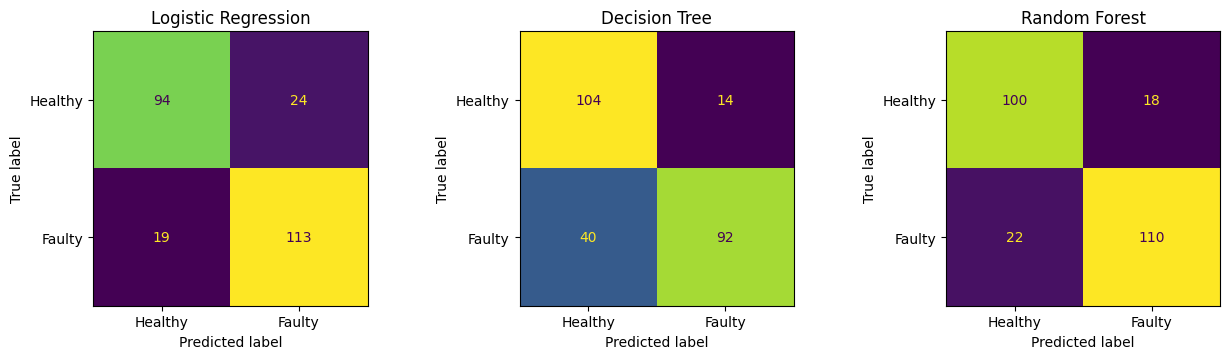

In [4]:
def evaluate_model(model, X_test, y_test):
    pred = model.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
    }


results = {name: evaluate_model(model, X_test, y_test) for name, model in models.items()}
print(pd.DataFrame(results).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, (name, model) in zip(axes, models.items(), strict=False):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["Healthy", "Faulty"], ax=ax, colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

## Part 5 — Random Forest Reasoning

**Q16** From the original five training observations `{A, B, C, D, E}`, identify which of these are valid bootstrap samples of size five and explain why:

(a) `{A, A, C, D, E}`  
(b) `{A, B, C, D}`  
(c) `{B, B, B, D, D}`

**Q17** Train Random Forests with `n_estimators = [1, 5, 20, 100]` and fixed `max_depth=4`, `random_state=42`. Plot test dataset Precision versus number of trees. Does adding more trees *guarantee* better test performance? Explain.

**Q18** Explain how random feature selection can make trees less correlated, and why averaging less-correlated trees can improve prediction stability.




## Answers

### Q16

(a) Valid: Contains five observations; repeated observations are allowed.

(b) Invalid: Contains only four observations; required sample size is five.

(c) Valid: Contains five observations. Repeating and omitting some original observations is allowed.

### Q17

Adding more trees doesn't guarantee better test precision. It normally reduces variance and makes predictions more stable, but precision on a particular test set can rise or fall, or remain the same, etc.

### Q18

Random feature selection gives each split a different subset of features to consider. This prevents every tree from repeatedly choosing the same strong predictors and encourages different tree structures, making their errors less correlated.

When the forest averages the trees’ class probabilities, individual errors can offset one another. This reduces variance and makes the final predictions more stable.

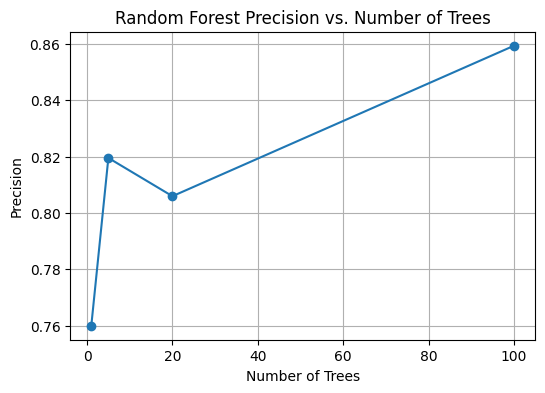

In [5]:
n_trees = [1, 5, 20, 100]
precision_values = []
for n_estimators in n_trees:
    random_forest = RandomForestClassifier(n_estimators=n_estimators, max_depth=4, random_state=42)
    random_forest.fit(X_train, y_train)  # Train the model

    predictions = random_forest.predict(X_test)
    precision = precision_score(y_test, predictions)

    precision_values.append(precision)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(n_trees, precision_values, marker="o")
ax.set_xlabel("Number of Trees")
ax.set_ylabel("Precision")
ax.set_title("Random Forest Precision vs. Number of Trees")
plt.grid()
plt.show()